In [1]:
# Imports

import pandas as pd
import json
import matplotlib.pyplot as plt

In [2]:
# Load

with open("data/weather.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data["hourly"], columns=["time", "temperature_2m"])

df["time"] = pd.to_datetime(df["time"], unit="s", utc=True)
df["time"] = df["time"].dt.tz_convert("America/Edmonton")

df = df.loc[df["time"].between("2000-01-01", "2026-01-01", inclusive="left")]

df.head()

,time,temperature_2m
0,2000-01-01 00:00:00-07:00,-4.5
1,2000-01-01 01:00:00-07:00,-4.6
2,2000-01-01 02:00:00-07:00,-4.7
3,2000-01-01 03:00:00-07:00,-6.9
4,2000-01-01 04:00:00-07:00,-7.2


In [3]:
# Inspect

# Structure
print(df["time"].min(), "to", df["time"].max(), "\n")
print("Shape:", df.shape, "\n")
print("Dtypes:")
print(df.dtypes, "\n")

# Missingness
print("Any Nulls:", df.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", df.duplicated().any())
print("Duplicate Times:", df["time"].duplicated().any(), "\n")

# Temporal Sanity
print("Non-Monotonic Times:", not df["time"].is_monotonic_increasing)
print("Unexpected Time Deltas:", df["time"].diff().dropna().ne(pd.Timedelta(hours = 1)).any(), "\n")

# Value Sanity
display(df[["temperature_2m"]].describe().T)

2000-01-01 00:00:00-07:00 to 2025-12-31 23:00:00-07:00 

Shape: (227928, 2) 

Dtypes:
time              datetime64[us, America/Edmonton]
temperature_2m                             float64
dtype: object 

Any Nulls: False 

Duplicate Rows: False
Duplicate Times: False 

Non-Monotonic Times: False
Unexpected Time Deltas: False 



,count,mean,std,min,25%,50%,75%,max
temperature_2m,227928.0,4.621072,11.630242,-100.0,-2.3,5.0,12.6,95.0


In [4]:
# Additional Inspect 
# Implausible Min and Max Temperatures

invalid = ~df["temperature_2m"].between(-45, 45)

print("Invalid Readings:", invalid.sum())
print(f"Invalid Readings %: {invalid.sum() / df["time"].count():.2%}")

# Sorted by Absolute Value to Check for Valid Values
display(df.loc[invalid, ["time", "temperature_2m"]].sort_values("temperature_2m", key = lambda x: x.abs(), ascending = False))

# Year Distribution of Invalid Temperatures
display(df.loc[invalid, "time"].dt.year.value_counts().sort_index())

Invalid Readings: 64
Invalid Readings %: 0.03%


,time,temperature_2m
223253,2025-06-20 06:00:00-06:00,-100.0
221561,2025-04-10 18:00:00-06:00,-100.0
223476,2025-06-29 13:00:00-06:00,-100.0
223474,2025-06-29 11:00:00-06:00,-100.0
223414,2025-06-26 23:00:00-06:00,-100.0
...,...,...
223231,2025-06-19 08:00:00-06:00,95.0
219243,2025-01-04 03:00:00-07:00,95.0
223381,2025-06-25 14:00:00-06:00,95.0
223427,2025-06-27 12:00:00-06:00,95.0


time
2025    64
Name: count, dtype: int64

In [5]:
# Clean

# Out-of-bounds temperatures are excluded.
# Preserve the hourly records, but exclude these measurements from monthly means.

clean_df = df.copy()

clean_df.loc[invalid, "temperature_2m"] = float("nan")

# Value Definitions

**Monthly anomaly**: The difference between a 2025 monthly mean and its corresponding historical average, in °C.

**Anomalous Month**: A month whose 2025 average temperature falls below the historical 10th percentile or above the historical 90th percentile.

In [6]:
# Transform 
# Monthly

# Monthly Averages
monthly_df = (clean_df.assign(year = lambda x: x["time"].dt.year,
                              month = lambda x: x["time"].dt.month)
                      .groupby(["year", "month"], as_index = False)
                      .agg(avg_temp = ("temperature_2m", "mean"),
                           valid_hours = ("temperature_2m", "count")))

# Historical Reference
reference_df = (monthly_df.loc[monthly_df["year"].between(2000, 2024)]
                          .groupby("month", as_index = False)
                          .agg(historical_avg = ("avg_temp", "mean"),
                               historical_p10 = ("avg_temp", lambda x: x.quantile(0.10)),
                               historical_p90 = ("avg_temp", lambda x: x.quantile(0.90)),
                               historical_years = ("avg_temp", "count")))

# Target Year
target_df = (monthly_df.loc[monthly_df["year"].eq(2025), ["month", "avg_temp", "valid_hours"]]
                       .rename(columns = {"avg_temp": "avg_2025"}))

# Calculate Anomalies
output_df = (target_df.merge(reference_df, on = "month", how = "inner", validate = "one_to_one")
                      .assign(anomaly = lambda x: x["avg_2025"] - x["historical_avg"],
                              lower_limit = lambda x: x["historical_p10"] - x["historical_avg"],
                              upper_limit = lambda x: x["historical_p90"] - x["historical_avg"],
                              unusually_cold = lambda x: x["avg_2025"].lt(x["historical_p10"]),
                              unusually_warm = lambda x: x["avg_2025"].gt(x["historical_p90"]))
                      .sort_values("month")
                      .round(2))

# Validation

assert output_df[["avg_2025", "historical_avg", "historical_p10", "historical_p90"]].notna().all().all()

print("Unusually Warm Months:", output_df.loc[output_df["unusually_warm"], "month"].tolist())
print("Unusually Cold Months:", output_df.loc[output_df["unusually_cold"], "month"].tolist())

display(output_df)

Unusually Warm Months: [5, 9]
Unusually Cold Months: []


,month,avg_2025,valid_hours,historical_avg,historical_p10,historical_p90,historical_years,anomaly,lower_limit,upper_limit,unusually_cold,unusually_warm
0,1,-4.14,737,-6.44,-9.83,-3.73,25,2.31,-3.39,2.71,False,False
1,2,-11.68,668,-6.61,-12.55,-2.66,25,-5.07,-5.94,3.95,False,False
2,3,0.37,742,-1.94,-5.98,2.53,25,2.31,-4.05,4.47,False,False
3,4,5.85,713,4.23,1.94,6.53,25,1.62,-2.29,2.29,False,False
4,5,12.83,736,10.28,8.53,12.28,25,2.55,-1.76,1.99,False,True
5,6,15.19,708,14.05,12.87,15.44,25,1.14,-1.18,1.39,False,False
6,7,16.02,738,17.35,15.74,19.27,25,-1.33,-1.61,1.92,False,False
7,8,17.16,740,16.13,14.29,17.93,25,1.03,-1.84,1.80,False,False
8,9,15.23,719,11.50,9.36,14.02,25,3.73,-2.13,2.52,False,True
9,10,6.24,738,4.75,1.80,7.39,25,1.49,-2.95,2.64,False,False


In [7]:
# Transform
# Daily

# Daily Averages
daily_avg_df = (clean_df.assign(date = lambda x: x["time"].dt.normalize())
                        .groupby("date", as_index = False)
                        .agg(avg_temp = ("temperature_2m", "mean"),
                             valid_hours = ("temperature_2m", "count"))
                        .assign(year = lambda x: x["date"].dt.year,
                                month_day = lambda x: x["date"].dt.strftime("%m-%d")))

# Historical Daily Observations
historical_daily_df = daily_avg_df.loc[daily_avg_df["year"].between(2000, 2024) &
                                       daily_avg_df["month_day"].ne("02-29")].copy()

historical_daily_df["day_index"] = pd.to_datetime("2001-" + historical_daily_df["month_day"]).dt.day_of_year

# Five-Day Historical Windows
window_df = pd.concat([
    historical_daily_df.assign(day_index = lambda x, offset = offset: (x["day_index"] + offset - 1) % 365 + 1)
    for offset in range(-2, 3)
], ignore_index = True)

# Historical Daily Reference
daily_reference_df = (window_df.groupby("day_index", as_index = False)
                               .agg(historical_avg = ("avg_temp", "mean"),
                                    historical_p10 = ("avg_temp", lambda x: x.quantile(0.10)),
                                    historical_p90 = ("avg_temp", lambda x: x.quantile(0.90)),
                                    historical_days = ("avg_temp", "count")))

# Target Year
daily_target_df = (daily_avg_df.loc[daily_avg_df["year"].eq(2025),
                                    ["date", "month_day", "avg_temp", "valid_hours"]]
                               .assign(day_index = lambda x: pd.to_datetime("2001-" + x["month_day"]).dt.day_of_year)
                               .rename(columns = {"avg_temp": "avg_2025"}))

# Calculate Daily Anomalies
daily_df = (daily_target_df.merge(daily_reference_df, on = "day_index", how = "inner", validate = "one_to_one")
                           .assign(anomaly = lambda x: x["avg_2025"] - x["historical_avg"],
                                   lower_limit = lambda x: x["historical_p10"] - x["historical_avg"],
                                   upper_limit = lambda x: x["historical_p90"] - x["historical_avg"],
                                   unusually_cold = lambda x: x["avg_2025"].lt(x["historical_p10"]),
                                   unusually_warm = lambda x: x["avg_2025"].gt(x["historical_p90"]))
                           .sort_values("date"))

# Validation

assert len(daily_df) == 365
assert daily_df[["avg_2025", "historical_avg", "historical_p10", "historical_p90"]].notna().all().all()

print("Unusually Warm Days:", daily_df["unusually_warm"].sum())
print("Unusually Cold Days:", daily_df["unusually_cold"].sum())

# Monthly Distribution of Unusual Days
display(daily_df.assign(month = lambda x: x["date"].dt.month)
                .groupby("month")[["unusually_warm", "unusually_cold"]]
                .sum())

# Largest Deviations Among Flagged Days
flagged = daily_df["unusually_warm"] | daily_df["unusually_cold"]

daily_output_df = (daily_df.loc[flagged, ["date", "anomaly", "lower_limit", "upper_limit"]]
                           .sort_values("anomaly", key = lambda x: x.abs(), ascending = False)
                           .head(10)
                           .round({"anomaly": 2, "lower_limit": 2, "upper_limit": 2})
                           .copy())

display(daily_output_df)

Unusually Warm Days: 69
Unusually Cold Days: 32


,unusually_warm,unusually_cold
month,,
1,4,0
2,8,10
3,6,0
4,5,0
5,12,0
6,6,2
7,4,12
8,2,0
9,9,0


,date,anomaly,lower_limit,upper_limit
33,2025-02-03 00:00:00-07:00,-18.06,-11.15,9.20
34,2025-02-04 00:00:00-07:00,-17.37,-11.25,9.16
32,2025-02-02 00:00:00-07:00,-17.00,-11.14,9.24
48,2025-02-18 00:00:00-07:00,-16.83,-10.24,8.00
47,2025-02-17 00:00:00-07:00,-16.10,-10.71,8.51
35,2025-02-05 00:00:00-07:00,-15.86,-11.67,9.26
45,2025-02-15 00:00:00-07:00,-14.91,-11.57,8.76
360,2025-12-27 00:00:00-07:00,-14.57,-12.25,8.73
49,2025-02-19 00:00:00-07:00,-14.47,-10.77,7.30
46,2025-02-16 00:00:00-07:00,-14.10,-10.92,8.87


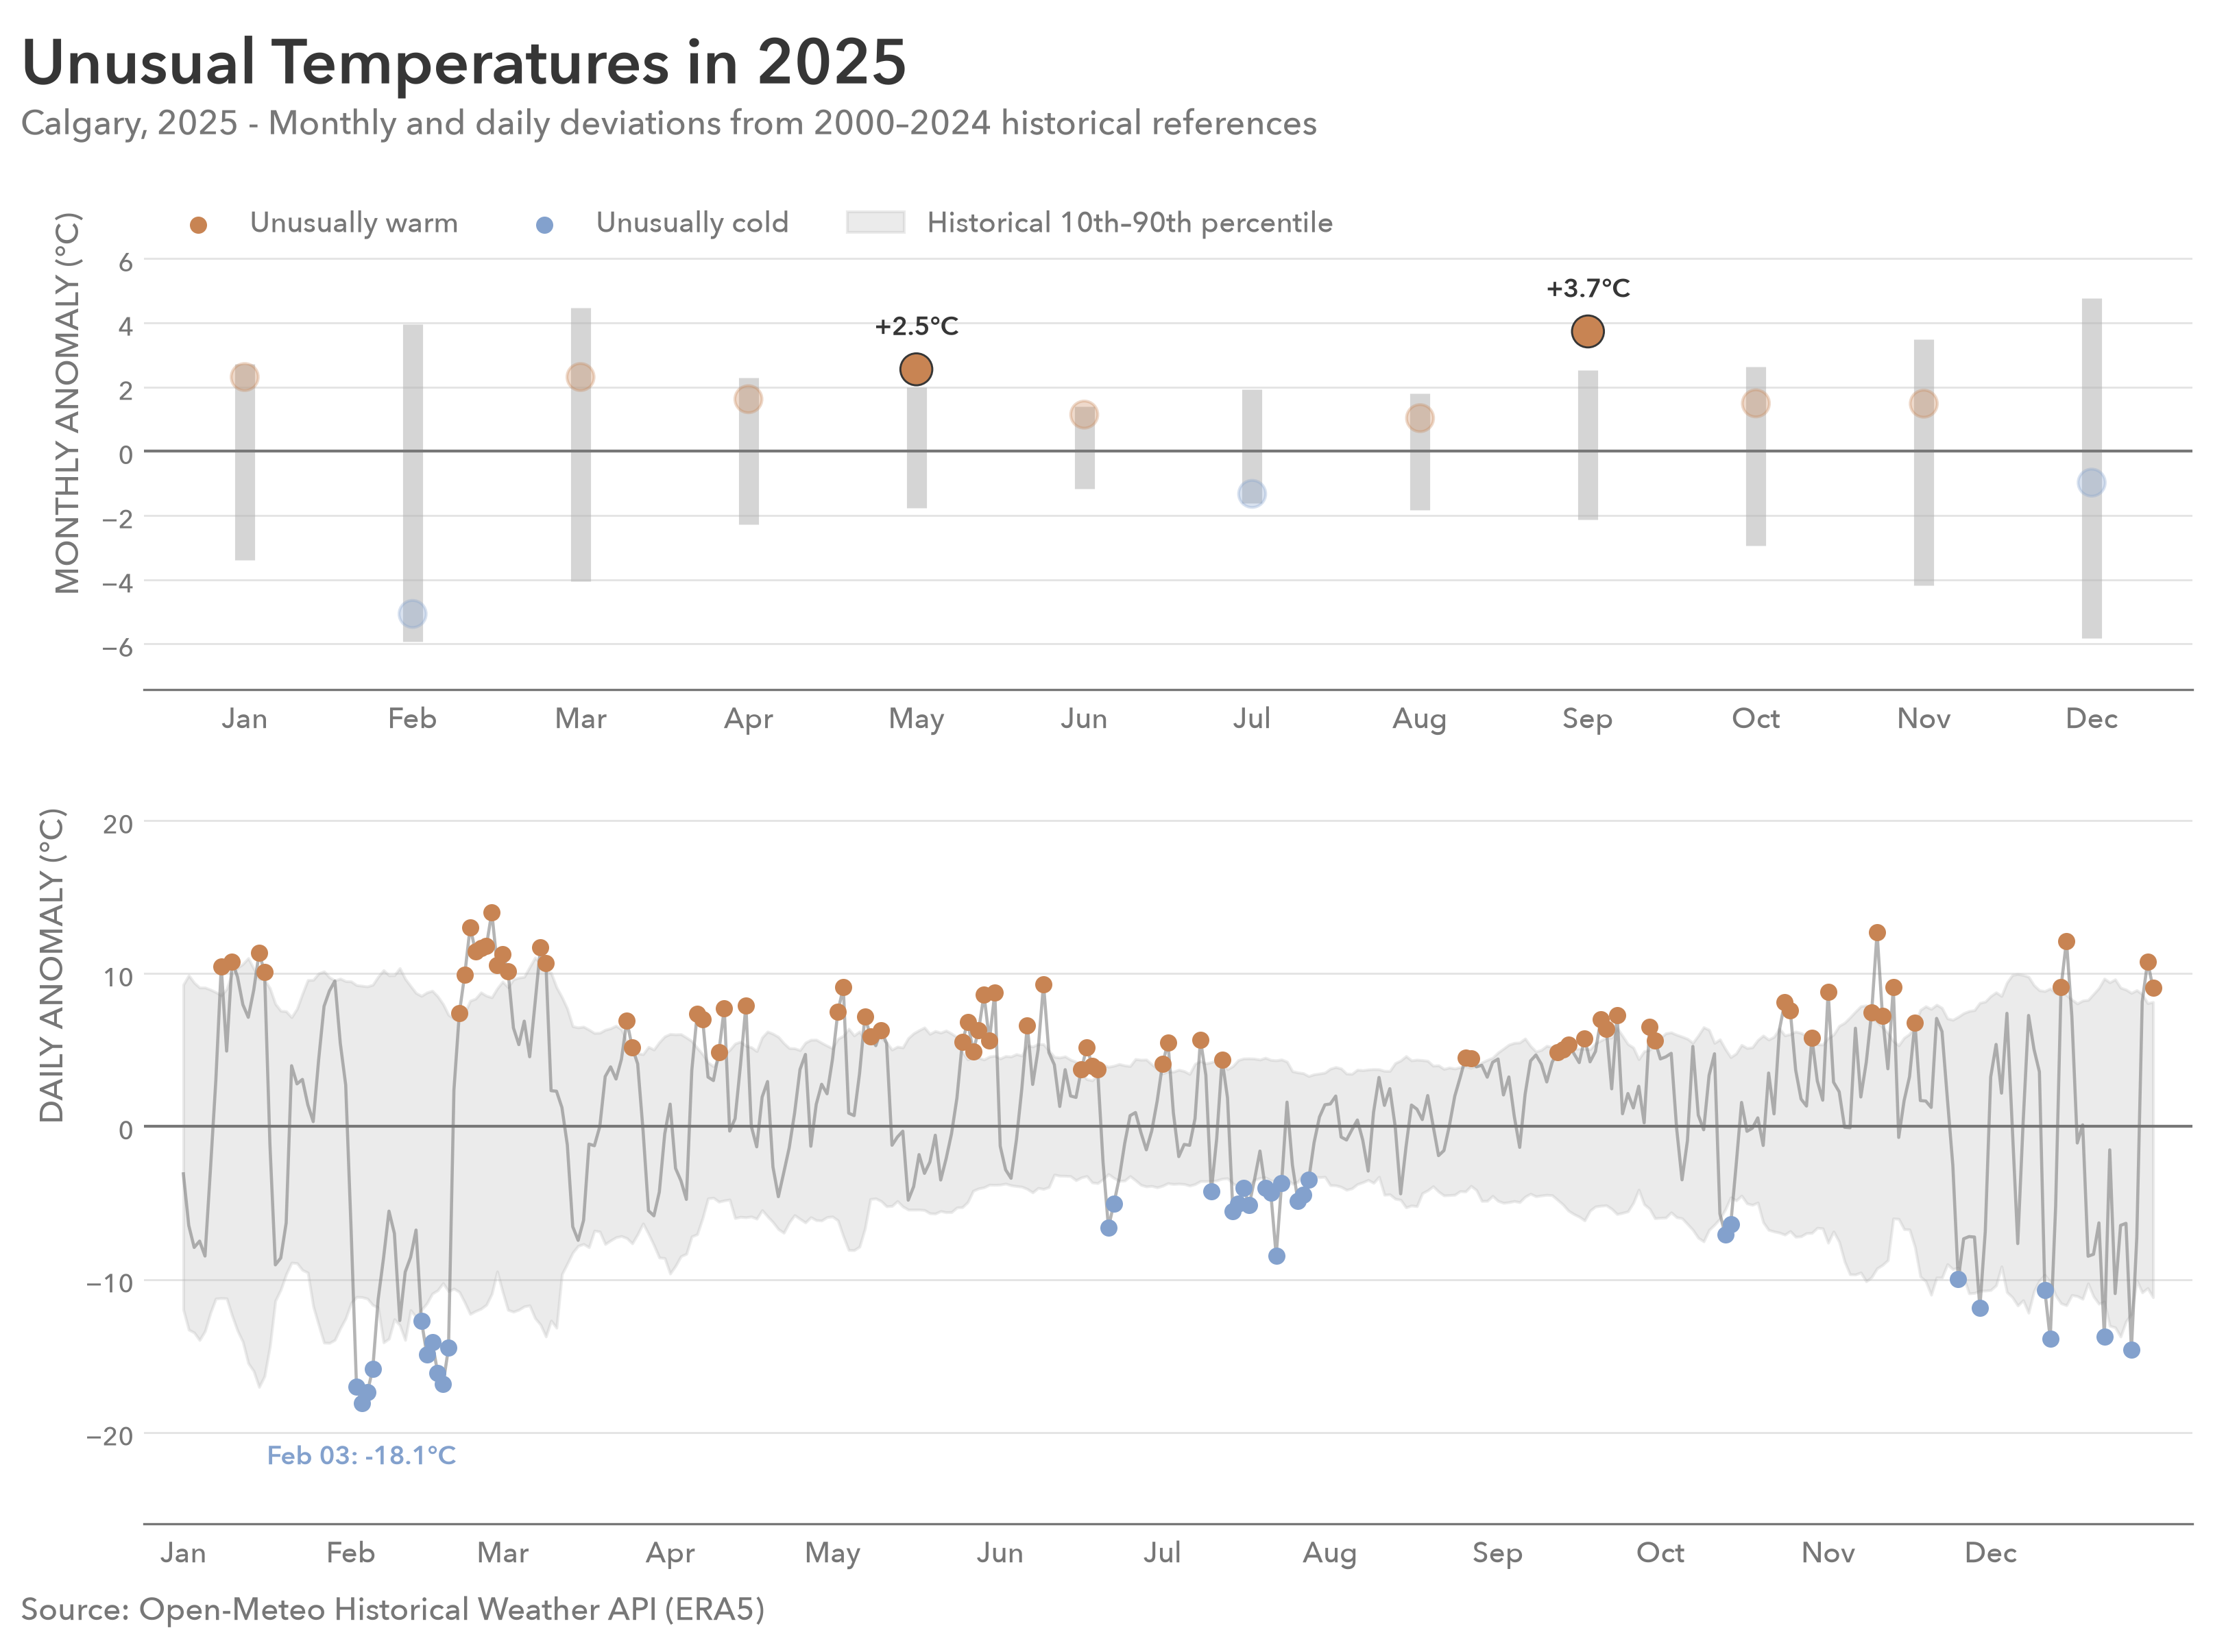

In [8]:
# Visualize

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 500

fig, (ax_month, ax_day) = plt.subplots(2, 1, figsize = (12, 8.5), dpi = 300, gridspec_kw = {"height_ratios": [1, 1.5]})

fig.subplots_adjust(
    left = 0.10,
    right = 0.93,
    top = 0.85,
    bottom = 0.10
)

STRUCTURE = "#777777"
GRID = "#B3B3B3"
BLUE = "#83A1CD"
ORANGE = "#C88453"
TITLE = "#363636"

# Plot

# monthly anomalies and historical intervals
months = output_df["month"]
anomalies = output_df["anomaly"]
flagged_months = output_df["unusually_warm"] | output_df["unusually_cold"]

colors = [ORANGE if value >= 0 else BLUE for value in anomalies]

ax_month.vlines(months, output_df["lower_limit"], output_df["upper_limit"], color = GRID, linewidth = 7, alpha = 0.55, zorder = 2)

ax_month.scatter(months, anomalies, s = 90, color = colors, alpha = 0.30, zorder = 3)
ax_month.scatter(months[flagged_months], anomalies[flagged_months], s = 125, color = [ORANGE if value >= 0 else BLUE for value in anomalies[flagged_months]], edgecolors = TITLE, linewidths = 0.7, zorder = 4)

# daily anomalies and historical intervals
band = ax_day.fill_between(daily_df["date"], daily_df["lower_limit"], daily_df["upper_limit"], color = GRID, alpha = 0.25, label = "Historical 10th–90th percentile")

ax_day.plot(daily_df["date"], daily_df["anomaly"], color = STRUCTURE, linewidth = 1.1, alpha = 0.55, zorder = 2)

warm_points = ax_day.scatter(daily_df.loc[daily_df["unusually_warm"], "date"], daily_df.loc[daily_df["unusually_warm"], "anomaly"], s = 25, color = ORANGE, label = "Unusually warm", zorder = 3)
cold_points = ax_day.scatter(daily_df.loc[daily_df["unusually_cold"], "date"], daily_df.loc[daily_df["unusually_cold"], "anomaly"], s = 25, color = BLUE, label = "Unusually cold", zorder = 3)

# Emphasis

# unusually warm months
ax_month.annotate("+2.5°C", (5, 2.55), xytext = (0, 12), textcoords = "offset points", ha = "center", fontsize = 9, fontweight = 600, color = TITLE)
ax_month.annotate("+3.7°C", (9, 3.73), xytext = (0, 12), textcoords = "offset points", ha = "center", fontsize = 9, fontweight = 600, color = TITLE)

# largest negative daily anomaly
ax_day.annotate("Feb 03: -18.1°C", (pd.Timestamp("2025-02-03", tz = "America/Edmonton"), -18.06),
                xytext = (0.06, 0.07), textcoords = "axes fraction",
                ha = "left", va = "bottom", fontsize = 9, fontweight = 600, color = BLUE)

# Scale & Axes

month_limit = output_df[["anomaly", "lower_limit", "upper_limit"]].abs().to_numpy().max() * 1.25
day_limit = daily_df[["anomaly", "lower_limit", "upper_limit"]].abs().to_numpy().max() * 1.15

ax_month.set_ylim(-month_limit, month_limit)
ax_day.set_ylim(-day_limit * 1.25, day_limit)

ax_month.set_xlim(0.4, 12.6)
ax_day.margins(x = 0.02)

ax_month.set_ylabel("MONTHLY ANOMALY (°C)", loc = "top", fontsize = 11, fontweight = 500, color = STRUCTURE)
ax_day.set_ylabel("DAILY ANOMALY (°C)", loc = "top", fontsize = 11, fontweight = 500, color = STRUCTURE)

# Ticks

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_starts = daily_df.loc[daily_df["date"].dt.day.eq(1), "date"]

ax_month.set_xticks(range(1, 13), month_names)
ax_day.set_xticks(month_starts, month_names)

ax_month.tick_params(axis = "x", labelsize = 10, length = 0, labelcolor = STRUCTURE)
ax_month.tick_params(axis = "y", labelsize = 9, length = 0, labelcolor = STRUCTURE)
ax_day.tick_params(axis = "x", labelsize = 10, length = 0, labelcolor = STRUCTURE)
ax_day.tick_params(axis = "y", labelsize = 9, length = 0, labelcolor = STRUCTURE)

# Styling

for ax in (ax_month, ax_day):
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color(STRUCTURE)

    ax.set_axisbelow(True)
    ax.grid(axis = "y", color = GRID, linewidth = 0.7, alpha = 0.35)
    ax.axhline(0, color = STRUCTURE, linewidth = 1)

# Composition

fig.suptitle("Unusual Temperatures in 2025", x = 0.05, y = 0.96, ha = "left", va = "top", fontweight = 600, fontsize = 22, color = TITLE)

fig.text(0.05, 0.895, "Calgary, 2025 - Monthly and daily deviations from 2000–2024 historical references", fontsize = 12, color = STRUCTURE)

fig.legend(handles = [warm_points, cold_points, band], loc = "upper left", bbox_to_anchor = (0.10, 0.87), ncol = 3, frameon = False, fontsize = 10, labelcolor = STRUCTURE)

fig.text(0.05, 0.045, "Source: Open-Meteo Historical Weather API (ERA5)", fontsize = 11, color = STRUCTURE)

# Output

fig.savefig("outputs/temperature-anomalies-monthly-daily-2025.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()